In [341]:
%pip install -q pandas numpy seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.


# Module 2.1 Assignment - K-means Clusterning

> Submitted by Phillip Amir Esguerra

In [342]:
# Imports
import pandas, numpy
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data Preparation

In [343]:
customer_data = pandas.read_csv("customer_data.csv")

print("Data Frame shape: ", customer_data.shape)

Data Frame shape:  (200, 6)


In [344]:
# Sample data
customer_data.head()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Purchase Frequency,Avg Purchase Value
0,1,56,84,71.905329,5.9,106.071893
1,2,69,86,38.482533,6.0,62.755253
2,3,46,41,38.967487,7.5,29.958887
3,4,32,23,10.002036,1.7,67.007220
4,5,60,76,56.350309,2.9,72.704110


In [345]:
customer_data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Purchase Frequency,Avg Purchase Value
count,200.000000,200.00000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,43.42500,67.145000,50.869302,5.335500,43.092021
std,57.879185,14.94191,31.249587,22.563855,2.687808,29.326249
min,1.000000,18.00000,15.000000,1.000000,0.600000,10.000000
25%,50.750000,31.00000,41.000000,32.366332,3.000000,17.651673
50%,100.500000,43.50000,66.500000,52.352457,5.450000,36.086311
75%,150.250000,56.00000,95.250000,67.224241,7.600000,59.641832
max,200.000000,69.00000,119.000000,100.000000,10.000000,137.621150


In [346]:
customer_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              200 non-null    int64  
 1   Age                     200 non-null    int64  
 2   Annual Income (k$)      200 non-null    int64  
 3   Spending Score (1-100)  200 non-null    float64
 4   Purchase Frequency      200 non-null    float64
 5   Avg Purchase Value      200 non-null    float64
dtypes: float64(3), int64(3)
memory usage: 9.5 KB


## 2. Exploratory Data Analysis

### Correlation Matrix of Customer Data

In [347]:

correlation_matrix = customer_data.corr()
correlation_matrix

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Purchase Frequency,Avg Purchase Value
CustomerID,1.000000,0.036668,0.012145,0.072500,-0.035033,0.116998
Age,0.036668,1.000000,-0.045936,0.020348,0.004427,0.024484
Annual Income (k$),0.012145,-0.045936,1.000000,0.598042,0.037133,0.367822
Spending Score (1-100),0.072500,0.020348,0.598042,1.000000,0.420496,0.184898
Purchase Frequency,-0.035033,0.004427,0.037133,0.420496,1.000000,-0.025963
Avg Purchase Value,0.116998,0.024484,0.367822,0.184898,-0.025963,1.000000


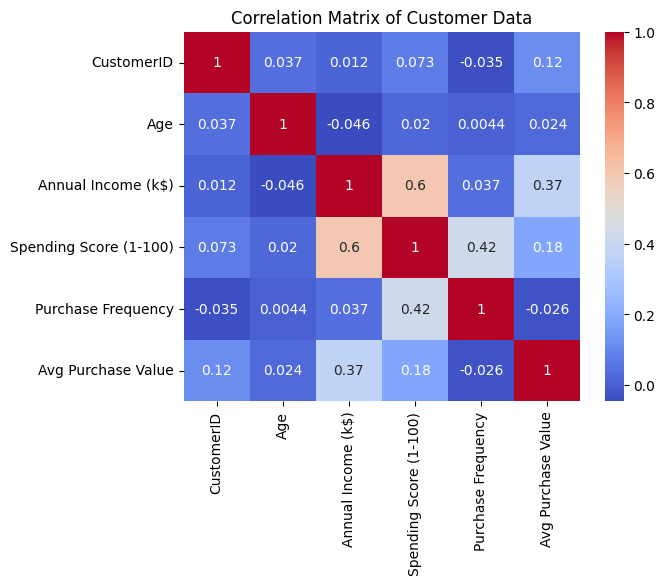

In [348]:
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix of Customer Data")
plt.show()

> This shows that annual income has a significant correlation with the spending score.
> Average purchase value and purchase frequency is also somewhat correlated with the annual income

### Comparing Correlated Variables

> Based from correlation matrix, we better compare the following variables:
> - Average Purchase Value vs Spending Score
> - Average Purchase Value vs Annual Income
> - Purchase Frequency vs Spending Score
> - Spending Score vs Annual Income

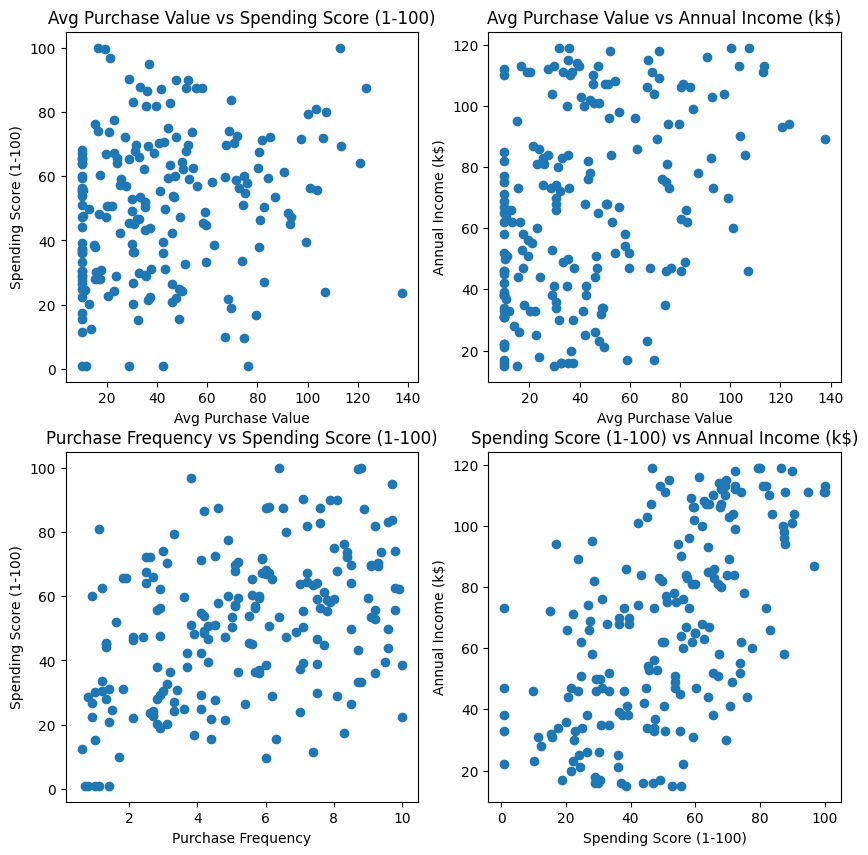

In [349]:
figure, axes = plt.subplots(2,2, figsize=(10, 10))
axes = axes.flatten()

var_pairs = [
    ("Avg Purchase Value", "Spending Score (1-100)"),
    ("Avg Purchase Value", "Annual Income (k$)"),
    ("Purchase Frequency", "Spending Score (1-100)"),
    ("Spending Score (1-100)", "Annual Income (k$)")
]

# Create scatter plots for each pair
for i, (x_var, y_var) in enumerate(var_pairs):
    axes[i].set_title(f"{x_var} vs {y_var}")
    axes[i].scatter(customer_data[x_var], customer_data[y_var])
    axes[i].set_xlabel(x_var)
    axes[i].set_ylabel(y_var)


### Distribution of Samples for each Variables

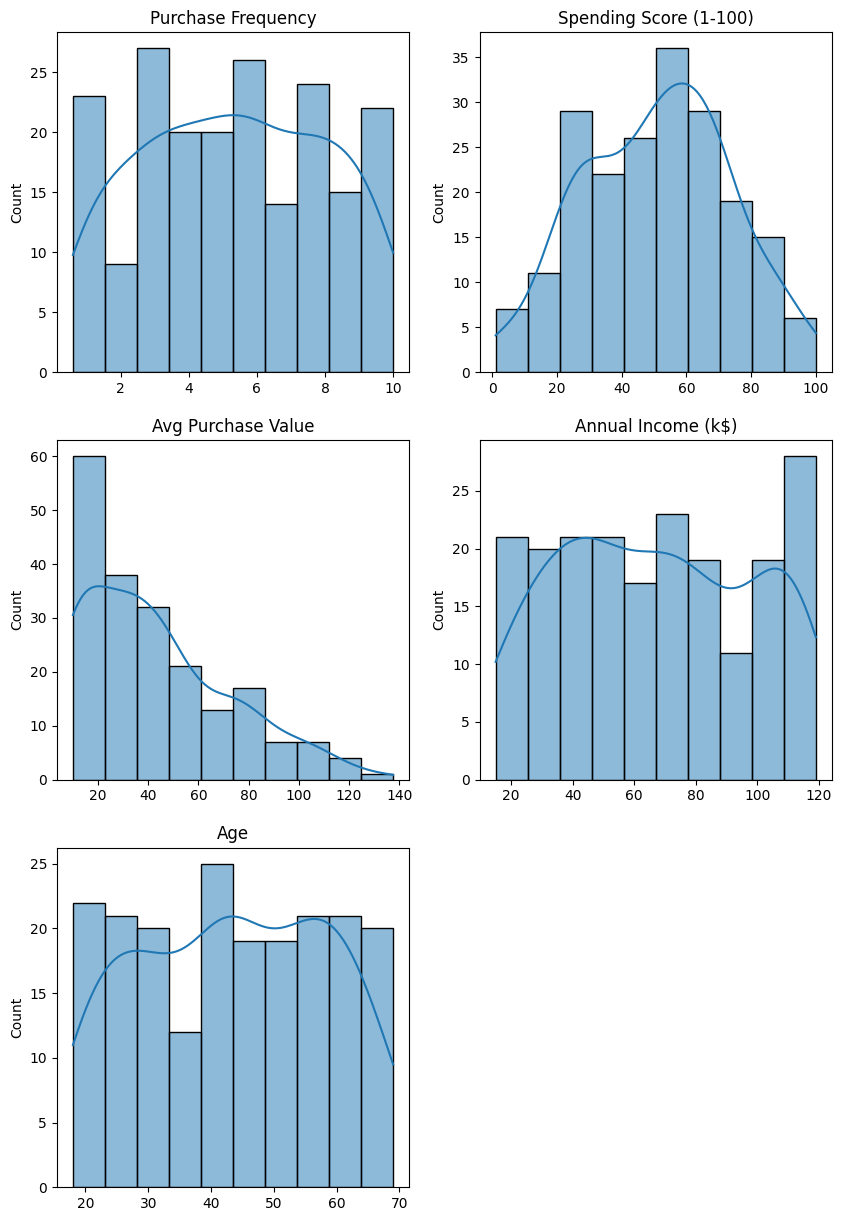

In [350]:
figure, axes = plt.subplots(3, 2, figsize=(10, 15))
axes = axes.flatten()

variables = [
    "Purchase Frequency", 
    "Spending Score (1-100)", 
    "Avg Purchase Value",
    "Annual Income (k$)",
    "Age"]

for i, var in enumerate(variables):
    sns.histplot(customer_data[var], bins=10, kde=True, ax=axes[i])
    axes[i].set_title(var)
    axes[i].set_xlabel("")

# Remove the unused subplot
figure.delaxes(axes[5])

plt.show()

## 3. Data Cleanup

In [351]:
# Based on customer_data.info() results, we can see that there are no missing values in the dataset.
# However, if there were missing values, we can handle them using the following
# We'll drop rows with any missing values since the dataset is small and we want to keep it clean.
customer_data.dropna(inplace=True)

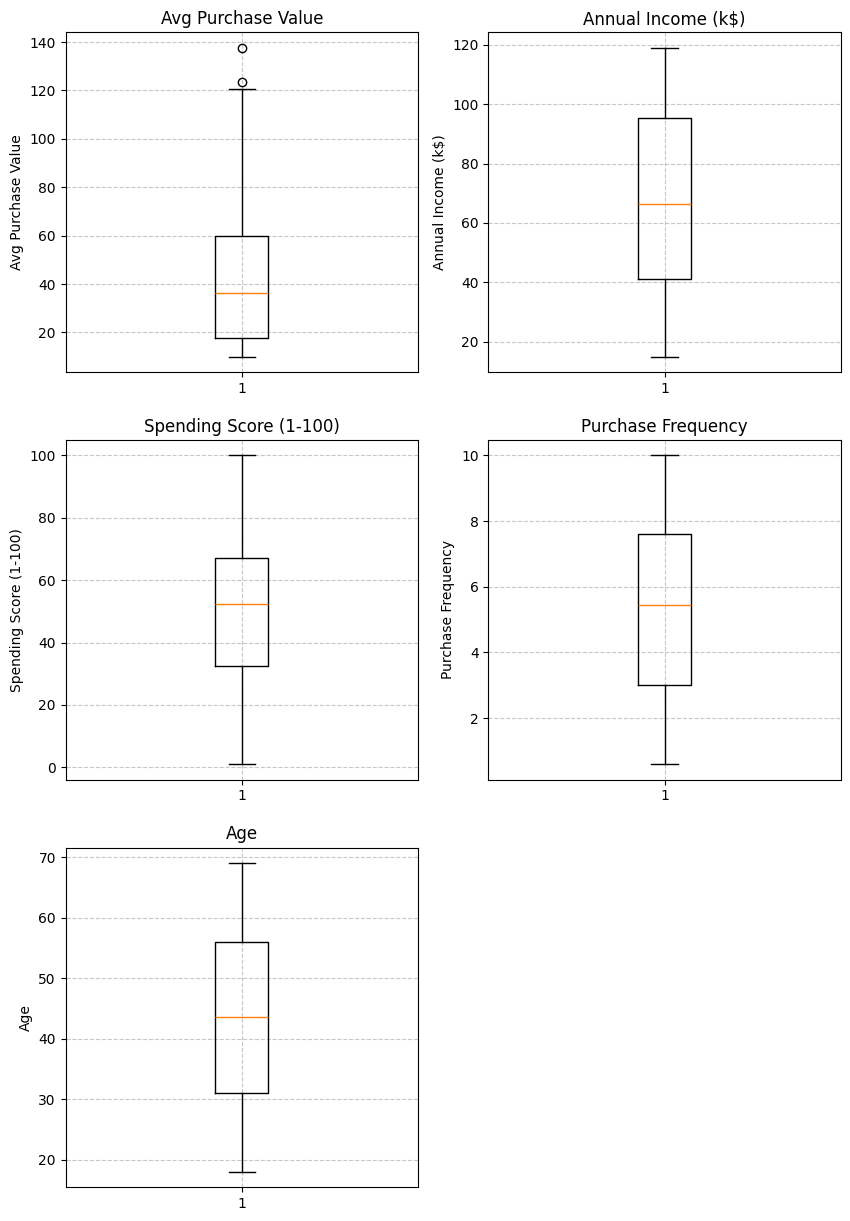

In [352]:
fig, axes = plt.subplots(3, 2, figsize=(10, 15))
axes = axes.flatten()

variables = [
    "Avg Purchase Value",
    "Annual Income (k$)",
    "Spending Score (1-100)", 
    "Purchase Frequency",
    "Age"
]

for i, var in enumerate(variables):
    axes[i].boxplot(customer_data[var])
    axes[i].set_title(var)
    axes[i].set_ylabel(var)
    axes[i].grid(True, linestyle="--", alpha=0.7)

fig.delaxes(axes[5])

plt.show()

> Looks like we got some outliers in Average Purchase Value. We can use `percentile` function in numpy to determine the outliers as described in the box plot.

In [353]:
def get_outliers(data, var):
    df = data[var]
    q1 = numpy.percentile(df, 25)
    q3 = numpy.percentile(df, 75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = data[(df < lower_bound) | (df > upper_bound)]
    return outliers, lower_bound, upper_bound


avg_purchase_value_outliers, lower_bound, upper_bound = get_outliers(customer_data, "Avg Purchase Value")
print("Outliers in Average Purchase Value:")
avg_purchase_value_outliers

Outliers in Average Purchase Value:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Purchase Frequency,Avg Purchase Value
47,48,35,89,23.631195,2.6,137.621150
132,133,52,94,87.592673,7.6,123.466386


In [354]:
average_purchase_value = customer_data["Avg Purchase Value"]
clean_customer_data = customer_data[(average_purchase_value >= lower_bound) & (average_purchase_value <= upper_bound)]
clean_customer_data.shape

(198, 6)

In [355]:
# Just need to make sure we don"t have outliers in other variables
vars = [
    "Annual Income (k$)", 
    "Spending Score (1-100)",
    "Purchase Frequency",
    "Age"
]

for var in vars:
    outliers, _, _ = get_outliers(customer_data, var)
    if not outliers.empty:
        print(f"Outliers in '{var}':")
        print(outliers.to_string())
    else:
        print(f"No outliers found in '{var}'.")


No outliers found in 'Annual Income (k$)'.
No outliers found in 'Spending Score (1-100)'.
No outliers found in 'Purchase Frequency'.
No outliers found in 'Age'.


> We expect the rows to be 198 now since we removed 2 outliers based on percentiles function above.

# 4. Data Normalization

In [356]:

from sklearn.preprocessing import MinMaxScaler, StandardScaler

scaler = MinMaxScaler()

columns_to_scale = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)",
    "Purchase Frequency",
    "Avg Purchase Value"
]

scaled_customer_data = clean_customer_data.copy()
scaled_customer_data[columns_to_scale] = scaler.fit_transform(scaled_customer_data[columns_to_scale])

scaled_customer_data.head()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Purchase Frequency,Avg Purchase Value
0,1,0.745098,0.663462,0.716215,0.563830,0.867614
1,2,1.000000,0.682692,0.378611,0.574468,0.476427
2,3,0.549020,0.250000,0.383510,0.734043,0.180246
3,4,0.274510,0.076923,0.090930,0.117021,0.514826
4,5,0.823529,0.586538,0.559094,0.244681,0.566274


<Axes: >

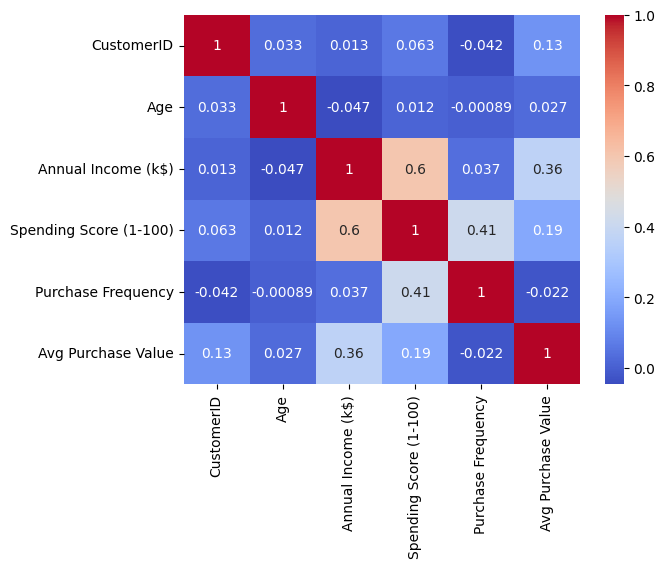

In [357]:
scaled_correlation_matrix = scaled_customer_data.corr()
scaled_correlation_matrix
sns.heatmap(scaled_correlation_matrix, annot=True, cmap="coolwarm")

> Correlation matrix is still the same even if we scaled it.

# 5. Determining the Optimal Number of Clusters - Elbow Method

/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/sklearn/cluster/_kmeans.py:1408: RuntimeWarning: algorithm='elkan' doesn't make sense for a single cluster. Using 'lloyd' instead.
  warnings.warn(


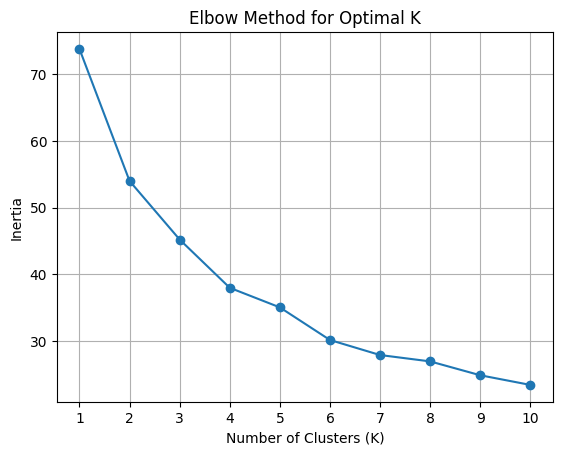

In [358]:
from sklearn.cluster import KMeans

k_max = 10
X = scaled_customer_data[[
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)",
    "Purchase Frequency",
    "Avg Purchase Value"
]].values

wcs = []
for k in range(1, k_max + 1):
    kmeans = KMeans(n_clusters=k, max_iter=420 , algorithm = "elkan", random_state=0)
    kmeans.fit(X)
    wcs.append(kmeans.inertia_)

plt.plot(range(1, k_max + 1), wcs, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, k_max + 1))
plt.grid(True)
plt.show()

> Looks like the optimial k is 2, 3, and 4.

# 6. Determining the Optimal Number of Clusters - Silhoutte Analysis

/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


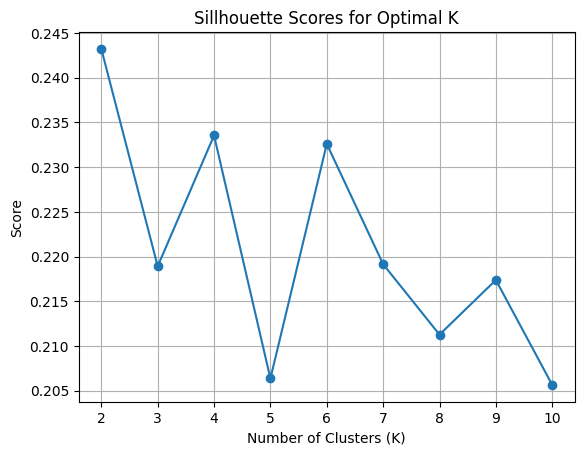

In [359]:
from sklearn.metrics import silhouette_score

k_max = 10
X = scaled_customer_data[[
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)",
    "Purchase Frequency",
    "Avg Purchase Value"
]].values

scores = []
# Got error when using k=1, says no score for 1 since data is in a single cluster 
for k in range(2, k_max + 1):
    kmeans = KMeans(n_clusters=k, max_iter=420, algorithm = "lloyd", random_state=0)
    clusters = kmeans.fit_predict(X)
    score = silhouette_score(X, clusters)
    scores.append(score)
    
plt.plot(range(2, k_max + 1), scores, marker="o")
plt.title("Sillhouette Scores for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Score")
plt.xticks(range(2, k_max + 1))
plt.grid(True)
plt.show()

> Looks like 2 got the higher score. Since we mentioned eearlier in Elbow method that 2,3,4 is ideal, then we'll settle with **cluster of 2.**

# 7. Clustering by KMeans 

In [360]:
var_pairs = [
    ("Avg Purchase Value", "Spending Score (1-100)"),
    ("Avg Purchase Value", "Annual Income (k$)"),
    ("Purchase Frequency", "Spending Score (1-100)"),
    ("Spending Score (1-100)", "Annual Income (k$)")
]

feature_columns = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)",
    "Purchase Frequency",
    "Avg Purchase Value"
]

Cluster characteristics for Avg Purchase Value and Spending Score (1-100):
               Age  Annual Income (k$)  Spending Score (1-100)  Purchase Frequency  Avg Purchase Value
Cluster                                                                                               
0        44.073529           82.617647               58.367345            5.457353           74.454079
1        43.084615           58.676923               46.874285            5.275385           25.341841

Cluster characteristics for Avg Purchase Value and Annual Income (k$):
               Age  Annual Income (k$)  Spending Score (1-100)  Purchase Frequency  Avg Purchase Value
Cluster                                                                                               
0        43.255814           96.116279               64.031097            5.641860           59.383229
1        43.553571           44.464286               40.678234            5.104464           29.021063

Cluster characteristics for 

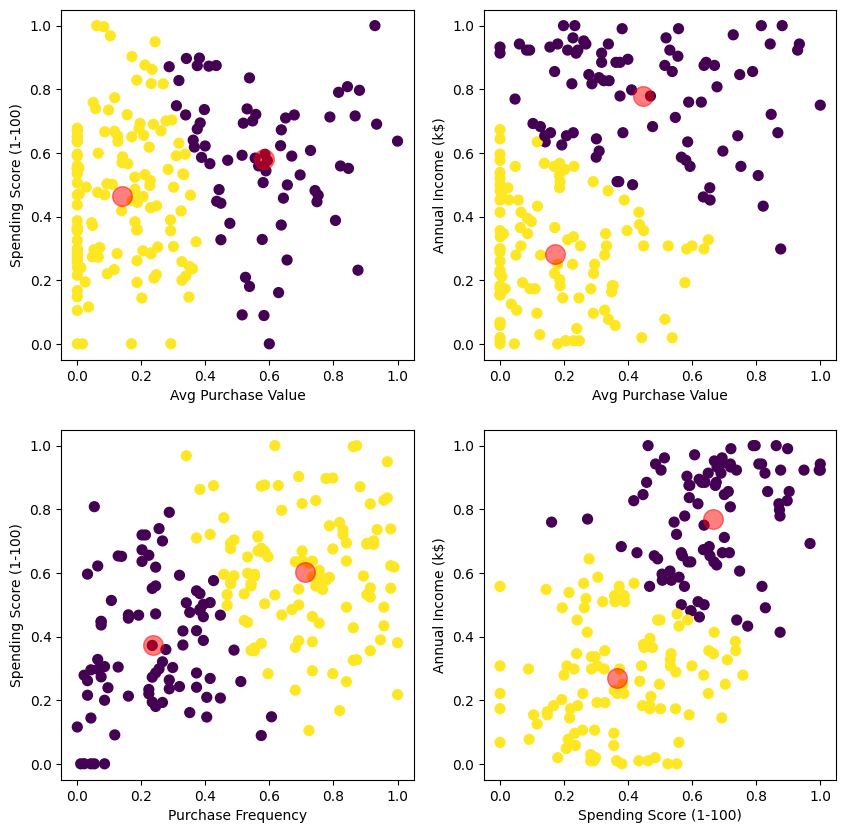

<Figure size 1000x1000 with 0 Axes>

<Figure size 1000x1000 with 0 Axes>

<Figure size 1000x1000 with 0 Axes>

<Figure size 1000x1000 with 0 Axes>

In [361]:
figure, axes = plt.subplots(2,2, figsize=(10, 10))
axes = axes.flatten()

customer_data_with_clusters = clean_customer_data.copy()

for i, (x_var, y_var) in enumerate(var_pairs):
    X = scaled_customer_data[[
        x_var, y_var
    ]].values
    
    kmeans = KMeans(n_clusters=2, max_iter=420, algorithm = "lloyd", random_state=0)
    customer_data_with_clusters["Cluster"] = kmeans.fit_predict(X)
    
    fig = plt.figure(figsize=(10, 10))
    
    axes[i].scatter(X[:, 0], X[:, 1], c=customer_data_with_clusters["Cluster"], s=50, cmap="viridis")

    axes[i].set_xlabel(x_var)
    axes[i].set_ylabel(y_var)

    centers = kmeans.cluster_centers_
    axes[i].scatter(centers[:, 0], centers[:, 1], c="red", s=200, alpha=0.5)
    
    print(f"Cluster characteristics for {x_var} and {y_var}:")
    cluster_characteristics = customer_data_with_clusters.groupby("Cluster")[feature_columns].mean()
    print(cluster_characteristics.to_string())
    print()

plt.show()


> Age is a fundamental demographic indicator so we include that in the next graphs

Mean cluster characteristics:
               Age  Annual Income (k$)  Spending Score (1-100)  Purchase Frequency  Avg Purchase Value
Cluster                                                                                               
0        43.314286           42.523810               36.918138            4.986667           33.213043
1        43.548387           94.419355               66.518623            5.734409           52.365023
Min val cluster characteristics:
         Age  Annual Income (k$)  Spending Score (1-100)  Purchase Frequency  Avg Purchase Value
Cluster                                                                                         
0         18                  15                1.000000                 0.6                10.0
1         18                  55               16.939937                 0.9                10.0
Max val cluster characteristics:
         Age  Annual Income (k$)  Spending Score (1-100)  Purchase Frequency  Avg Purchase Value
Cluster

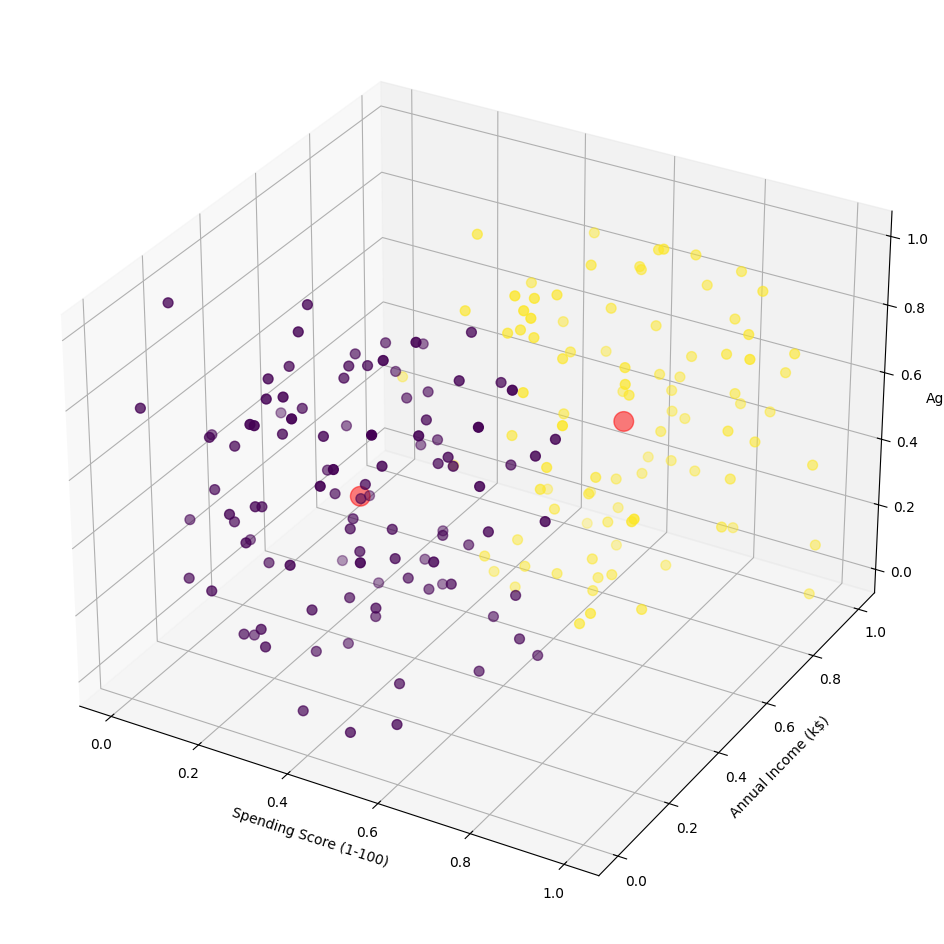

<Figure size 1000x1000 with 0 Axes>

In [362]:
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(projection='3d')

customer_data_with_clusters = clean_customer_data.copy()

X = scaled_customer_data[[
    "Spending Score (1-100)", "Annual Income (k$)", "Age"
]].values

kmeans = KMeans(n_clusters=2, max_iter=420, algorithm = "lloyd", random_state=0)
customer_data_with_clusters["Cluster"] = kmeans.fit_predict(X)
fig = plt.figure(figsize=(10, 10))

ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=customer_data_with_clusters["Cluster"], s=50, cmap="viridis")
ax.set_xlabel("Spending Score (1-100)")
ax.set_ylabel("Annual Income (k$)")
ax.set_zlabel("Age")
centers = kmeans.cluster_centers_
ax.scatter(centers[:, 0], centers[:, 1], centers[:, 2], c="red", s=200, alpha=0.5)

print(f"Mean cluster characteristics:")
print(customer_data_with_clusters.groupby("Cluster")[feature_columns].mean().to_string())
print("======")
print(f"Min val cluster characteristics:")
print(customer_data_with_clusters.groupby("Cluster")[feature_columns].min().to_string())
print("======")
print(f"Max val cluster characteristics:")
print(customer_data_with_clusters.groupby("Cluster")[feature_columns].max().to_string())
print("======")

plt.show()


## Interpretation

Based on the cluster characteristics for the 2 clusters, we can conclude the following::
- Both clusters 0 and 1 has an average age of around ~43
- Clusters 0 and 1 has an average annual income of ~95.07k and ~42.93k $, respectively
- Average spending scores of clusters 0 and 1 is 66.7 and 37.31, respectively
- Purchase frequencies for both clusters are the similar at around ~5
- Cluster 0's average purchase value is 55 while Cluster 1's is 33.02